# LM16 Lab — Joint Distributions and Dependence

Companion notebook to **From Calculus to Kelly, LM16**. It repairs the sector closes, rebuilds the module's exhibits and computational examples, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | Data: the served sector closes, the repair cell (rule and counts), returns, $T$ and $A$; the pair, S5 and the TAIEX price index |
| 2 | The joint pmf of the bins with the guard and with `Fraction` (Exhibit 2, Example 1) |
| 3 | Today's move and tomorrow's (Example 4, Exhibit 3) |
| 4 | Sums and portfolios: Example 5 (model value = sample value), the model year of Section 4, Problem 5 |
| 5 | The tower property and the law of total variance (Exhibit 4, Example 6), Problem 6 |
| 6 | The normal pair and $\chi^2$: Example 7, Exhibit 5, Exhibit 6, Example 8, Example 9, the knowledge check of Section 6, Problems 7 and 8 |
| 7 | Correlation in a crash: Exhibit 9 with `quad`, Exhibit 8, Example 10, Problem 10 |
| 8 | Problem 12 and an extension exercise (the two price-limit regimes) |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

`data/` then holds `sectors_close_raw.csv` (the closes FinMind's `TaiwanStockPrice` serves for TAIEX and the 30 TWSE sector indices, one column per series, empty where a series has no close) and `sectors_close_repairs.csv` (each of the 561 closes that FinMind copied from another date or series, with its official 13:30:00 value from `TaiwanStockEvery5SecondsIndex`). The notebook reads nothing outside `data/`.

**Conventions (as in the module).** Daily simple price returns (no dividends) between consecutive TAIEX-calendar dates; the U28 sample (the 28 leaf indices among the 30 TWSE sector indices, all but the aggregates Electronic and ChemicalBiotechnologyMedicalCare) and the TAIEX price index, closes 2008-12-01 to 2026-10-08, $T=4{,}382$ returns. Moments divide by $T$ (a bin's by its days). Every count against an edge uses the guard `1e-12`. Counts and correlations are descriptive; the normal model uses the same days' moments (in-sample); the regime comparison at the end is a stability check.

In [1]:
from fractions import Fraction
from pathlib import Path
import math
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from scipy import integrate, stats
from scipy.linalg import solve_triangular

DATA = Path("data")
FIRST_CLOSE, LAST_CLOSE = "2008-12-01", "2026-10-08"
AGGREGATES = ["Electronic", "ChemicalBiotechnologyMedicalCare"]
S5 = ["Semiconductor", "FinancialInsurance", "Food", "Plastics", "ShippingTransportation"]
EPS = 1e-12                       # the guard at every edge: two-decimal closes make round returns exact ties
pl.Config.set_tbl_rows(40)
pl.Config.set_float_precision(6)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## Part 1 — Data and the repair cell

FinMind's `TaiwanStockPrice` serves the sector indices with some rows copied from another date, or from another series on the same date (PITFALLS §3 of the repository). The book replaces each of these 561 closes with the official 13:30:00 value. On FinMind's free plan the 13:30:00 values are not available (`TaiwanStockEvery5SecondsIndex` is a paid dataset), so `close_1330` is empty and the cell **drops** those closes instead: a dropped close removes the returns into and out of its date, and the common sample shrinks from 4,382 to 4,307 returns, as in the LM12 lab. Nothing is ever estimated.

In [2]:
raw = pl.read_csv(DATA / "sectors_close_raw.csv", infer_schema_length=None).sort("date")
rep = pl.read_csv(DATA / "sectors_close_repairs.csv", infer_schema_length=None,
                  schema_overrides={"close_1330": pl.Float64})
series = [c for c in raw.columns if c != "date"]
fixed = raw
for sid in rep["id"].unique(maintain_order=True).to_list():
    g = rep.filter(pl.col("id") == pl.lit(sid)).select("date", pl.col("close_1330").alias("_new"),
                                                        pl.lit(True).alias("_listed"))
    fixed = (fixed.join(g, on="date", how="left").sort("date")
                  .with_columns(pl.when(pl.col("_listed")).then(pl.col("_new")).otherwise(pl.col(sid)).alias(sid))
                  .drop("_new", "_listed"))
n_listed = rep.height
n_replaced = int(rep["close_1330"].is_not_null().sum())
U28 = [c for c in series if c not in ("TAIEX", *AGGREGATES)]
in_sample = rep.filter((pl.col("date") >= pl.lit(FIRST_CLOSE)) & (pl.col("date") <= pl.lit(LAST_CLOSE))
                       & pl.col("id").is_in(U28))
FULL_DATA = n_replaced == n_listed
print("Rule: every close listed in sectors_close_repairs.csv is replaced by its 13:30:00 value (close_1330);")
print("      a listed close without that value is dropped (set to missing), never estimated.")
print(f"listed closes {n_listed}: replaced {n_replaced}, dropped {n_listed - n_replaced}")
print(f"in this module's sample (U28): {in_sample.height} closes on {in_sample['date'].n_unique()} dates")

Rule: every close listed in sectors_close_repairs.csv is replaced by its 13:30:00 value (close_1330);
      a listed close without that value is dropped (set to missing), never estimated.
listed closes 561: replaced 561, dropped 0
in this module's sample (U28): 524 closes on 38 dates


In [3]:
closes = fixed.filter(pl.col("date").is_between(pl.lit(FIRST_CLOSE), pl.lit(LAST_CLOSE))).sort("date")
ret = (closes.with_columns([(pl.col(c) / pl.col(c).shift(1) - 1).alias(c) for c in series])
             .with_columns(pl.col("date").shift(1).alias("prev"))
             .slice(1))
smp = ret.filter(pl.all_horizontal([pl.col(c).is_not_null() for c in ["TAIEX", *U28]]))
T = smp.height
dates = smp["date"].to_list()
X = smp.select(U28).to_numpy()
RT = smp["TAIEX"].to_numpy()                       # the TAIEX price index (no dividends) on the same dates
col = {c: i for i, c in enumerate(U28)}
x1, x2 = X[:, col["Semiconductor"]], X[:, col["FinancialInsurance"]]
years = (np.datetime64(LAST_CLOSE) - np.datetime64(FIRST_CLOSE)).astype(int) / 365.25
A = T / years
print(f"common sample: T = {T} returns, {dates[0]} .. {dates[-1]}; X is {X.shape}; A = {A:.4f}")


def show(label, value, fmt, printed, kept=False):
    # print a value next to the module's printed value; assert equality when every close is repaired, or when the
    # number cannot change on the free plan (constructed inputs, the module's printed inputs, untouched dates)
    got = format(value, fmt)
    note = "" if got == printed else ("   (differs: closes were dropped)" if not (FULL_DATA or kept) else "   MISMATCH")
    print(f"{label}: {got}   [book: {printed}]{note}")
    if FULL_DATA or kept:
        assert got == printed, (label, got, printed)


show("T", T, ",", "4,382")
show("A", A, ".2f", "245.48")
show("listed U28 closes in the sample", in_sample.height, "d", "524", kept=True)
show("   on dates", in_sample["date"].n_unique(), "d", "38", kept=True)

common sample: T = 4382 returns, 2008-12-02 .. 2026-10-08; X is (4382, 28); A = 245.4794
T: 4,382   [book: 4,382]
A: 245.48   [book: 245.48]
listed U28 closes in the sample: 524   [book: 524]
   on dates: 38   [book: 38]


**Which numbers change on the free plan.** With the listed closes dropped, the sample keeps $T=4{,}307$ returns, and every full-sample statistic changes slightly: moments, correlations, counts, $d_t^2$ and the model values fitted to them. Numbers computed from the module's printed inputs (the hand examples and problems), the constructed examples and the raw returns of 7–9 April 2025 and 5 August 2024 do not change. `show(...)` asserts equality only where the value cannot change.

## Part 2 — The joint pmf of the bins

**Exhibit 2 and Example 1.** Each sector's daily return is binned at $\le-1\%$, between, $\ge1\%$, with the guard. The exact recount uses `fractions.Fraction` on the two-decimal closes: `Fraction("1234.56")` is exact, and so is every return built from it.

In [4]:
def bin_expr(c):
    return (pl.when(pl.col(c) <= -0.01 + EPS).then(pl.lit("1 down"))
              .when(pl.col(c) >= 0.01 - EPS).then(pl.lit("3 up"))
              .otherwise(pl.lit("2 between")))


bins = smp.select(bin_expr("Semiconductor").alias("Semiconductor"), bin_expr("FinancialInsurance").alias("Fin"))
counts = bins.group_by("Semiconductor", "Fin").len().sort("Semiconductor", "Fin")
cell = {(r["Semiconductor"], r["Fin"]): r["len"] for r in counts.iter_rows(named=True)}
labs = ["1 down", "2 between", "3 up"]
table = pl.DataFrame({"Semiconductor": labs, **{f: [cell.get((s, f), 0) for s in labs] for f in labs}})
table = table.with_columns(pl.sum_horizontal(labs).alias("total"))
table   # Exhibit 2: rows Semiconductor, columns FinancialInsurance

Semiconductor,1 down,2 between,3 up,total
str,i64,i64,i64,i64
"""1 down""",347,478,34,859
"""2 between""",171,2100,248,2519
"""3 up""",20,654,330,1004


In [5]:
# exact recount with Fraction on the closes of the dates in the sample (each return needs its own previous close)
cl = closes.select("date", "Semiconductor", "FinancialInsurance").to_dicts()
cur = {row["date"]: row for row in cl}
prev = {cl[i]["date"]: cl[i - 1] for i in range(1, len(cl))}
one = Fraction(1, 100)


def exact(d, c):
    # the exact return on date d: two-decimal closes parse exactly from their decimal strings
    return Fraction(str(cur[d][c])) / Fraction(str(prev[d][c])) - 1


tabF = {}
ties = 0
for d in dates:
    u, v = exact(d, "Semiconductor"), exact(d, "FinancialInsurance")
    ties += (u in (one, -one)) + (v in (one, -one))
    key = (0 if u <= -one else 2 if u >= one else 1, 0 if v <= -one else 2 if v >= one else 1)
    tabF[key] = tabF.get(key, 0) + 1
print("Fraction recount equals the guarded count:",
      all(tabF.get((i, j), 0) == cell.get((labs[i], labs[j]), 0) for i in range(3) for j in range(3)),
      "| returns of exactly +-1%:", ties)

Fraction recount equals the guarded count: True | returns of exactly +-1%: 0


In [6]:
n_ll, n_r0, n_c0 = cell[("1 down", "1 down")], table["total"][0], int(table["1 down"].sum())
show("Example 1 Pr(both <= -1%)", n_ll / T, ".4f", "0.0792")
show("   Pr(Semiconductor <= -1%)", n_r0 / T, ".4f", "0.1960")
show("   Pr(FinancialInsurance <= -1%)", n_c0 / T, ".4f", "0.1228")
show("   product of the printed margins", 0.1960 * 0.1228, ".4f", "0.0241", kept=True)
show("   joint / product, printed values", 0.0792 / 0.0241, ".2f", "3.29", kept=True)
show("   Pr(Fin <= -1% | Semi <= -1%)", n_ll / n_r0, ".3f", "0.404")
show("   Pr(Fin <= -1% | Semi >= 1%)", cell[("3 up", "1 down")] / table["total"][2], ".4f", "0.0199")
show("knowledge check: Pr(Semi >= 1% | Fin <= -1%)", cell[("3 up", "1 down")] / n_c0, ".4f", "0.0372")

Example 1 Pr(both <= -1%): 0.0792   [book: 0.0792]
   Pr(Semiconductor <= -1%): 0.1960   [book: 0.1960]
   Pr(FinancialInsurance <= -1%): 0.1228   [book: 0.1228]
   product of the printed margins: 0.0241   [book: 0.0241]
   joint / product, printed values: 3.29   [book: 3.29]
   Pr(Fin <= -1% | Semi <= -1%): 0.404   [book: 0.404]
   Pr(Fin <= -1% | Semi >= 1%): 0.0199   [book: 0.0199]
knowledge check: Pr(Semi >= 1% | Fin <= -1%): 0.0372   [book: 0.0372]


## Part 3 — Today's move and tomorrow's

**Example 4 and Exhibit 3.** The TAIEX price index on the U28 dates: 4,381 pairs $(R_t,R_{t+1})$, grouped by $R_t$ in bins $(\text{lower},\text{upper}]$ split at $-3,\dots,3\%$, with the guard.

In [7]:
tx = pl.DataFrame({"R": RT[:-1], "next": RT[1:]})
c_ret = np.corrcoef(RT[:-1], RT[1:])[0, 1]
c_abs = np.corrcoef(np.abs(RT[:-1]), np.abs(RT[1:]))[0, 1]
show("Example 4 pairs", tx.height, ",", "4,381")
show("   corr(R_t, R_t+1)", c_ret, ".3f", "0.040")
show("   corr(|R_t|, |R_t+1|)", c_abs, ".3f", "0.183")
big = tx.filter(pl.col("R").abs() >= 0.02 - EPS)
other = tx.filter(pl.col("R").abs() < 0.02 - EPS)
show("   days with |R_t| >= 2%", big.height, "d", "306")
show("   mean |R_t+1| after them, %", 100 * big["next"].abs().mean(), ".2f", "1.28")
show("   after the others, %", 100 * other["next"].abs().mean(), ".2f", "0.75")
show("   overall, %", 100 * tx["next"].abs().mean(), ".2f", "0.79")
edges = [-0.03, -0.02, -0.01, 0.0, 0.01, 0.02, 0.03]
binned = (tx.with_columns(pl.col("R").cut([e + EPS for e in edges]).alias("bin"))
            .group_by("bin").agg(pl.len().alias("days"), (100 * pl.col("R").mean()).alias("mean R_t %"),
                                 (100 * pl.col("next").mean()).alias("mean R_t+1 %"),
                                 (100 * pl.col("next").abs().mean()).alias("mean |R_t+1| %"))
            .sort("mean R_t %"))
binned   # Exhibit 3

Example 4 pairs: 4,381   [book: 4,381]
   corr(R_t, R_t+1): 0.040   [book: 0.040]
   corr(|R_t|, |R_t+1|): 0.183   [book: 0.183]
   days with |R_t| >= 2%: 306   [book: 306]
   mean |R_t+1| after them, %: 1.28   [book: 1.28]
   after the others, %: 0.75   [book: 0.75]
   overall, %: 0.79   [book: 0.79]


C:\Users\ben0315\AppData\Local\Temp\ipykernel_61172\189102359.py:14: DeprecationWarning: `cut` is deprecated; use `bin_intervals` instead
  binned = (tx.with_columns(pl.col("R").cut([e + EPS for e in edges]).alias("bin"))


bin,days,mean R_t %,mean R_t+1 %,mean |R_t+1| %
enum,u32,f64,f64,f64
"""(-inf, -0.029999999999]""",60,-4.141625,-0.061432,2.015246
"""(-0.029999999999, -0.019999999…",95,-2.449421,0.224462,1.202650
"""(-0.019999999999, -0.009999999…",389,-1.387712,0.003727,0.905722
"""(-0.009999999999, 0.0000000000…",1433,-0.403261,0.003857,0.804310
"""(0.000000000001, 0.01000000000…",1770,0.430486,0.072980,0.695982
"""(0.010000000001, 0.02000000000…",483,1.386655,0.136642,0.692518
"""(0.020000000001, 0.03000000000…",112,2.417433,0.287673,0.925929
"""(0.030000000000999998, inf]""",39,4.227666,0.488103,1.371819


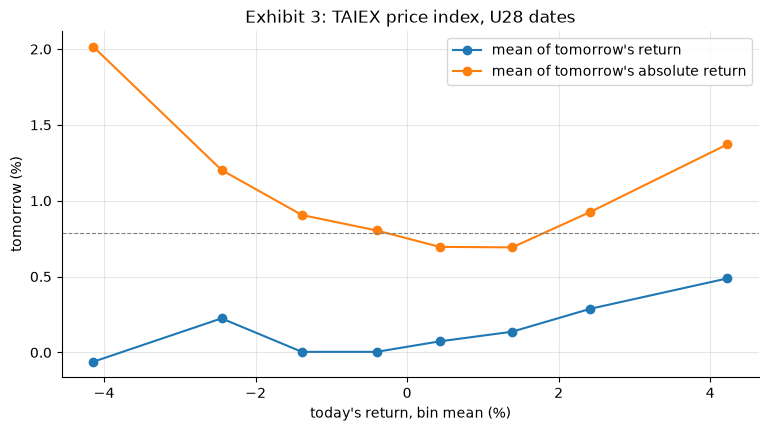

In [8]:
fig, ax = plt.subplots()
ax.plot(binned["mean R_t %"], binned["mean R_t+1 %"], marker="o", label="mean of tomorrow's return")
ax.plot(binned["mean R_t %"], binned["mean |R_t+1| %"], marker="o", label="mean of tomorrow's absolute return")
ax.axhline(100 * tx["next"].abs().mean(), ls="--", color="gray", lw=0.8)
ax.set_xlabel("today's return, bin mean (%)"); ax.set_ylabel("tomorrow (%)")
ax.set_title("Exhibit 3: TAIEX price index, U28 dates"); ax.legend(); plt.show()

## Part 4 — Sums and portfolios

**Example 5.** Under the empirical distribution the model's value is the sample value: the variance of the 50/50 portfolio's daily returns equals $\mathbf w^{\top}\hat\Sigma\mathbf w$ exactly (divisor $T$). Then the model year of Section 4 and Problem 5.

In [9]:
XP = np.column_stack([x1, x2])
Sig = np.cov(XP, rowvar=False, ddof=0)            # divisor T, as (10.2); np.cov's default divides by T - 1
w = np.array([0.5, 0.5])
rp = XP @ w
print(f"variance of the 50/50 returns {rp.var():.15e} = w' Sigma w {w @ Sig @ w:.15e}; "
      f"gap {abs(rp.var() - w @ Sig @ w):.1e}")
assert abs(rp.var() - w @ Sig @ w) < 1e-18
AS = A * Sig * 1e4                                # annualized, in %^2
show("LM10's annualized matrix: sigma_1^2", AS[0, 0], ".2f", "570.34")
show("   sigma_12", AS[0, 1], ".2f", "261.83")
show("   sigma_2^2", AS[1, 1], ".2f", "363.73")
s11, s12, s22 = 570.34, 261.83, 363.73            # the module's printed inputs
vp = 0.25 * s11 + 0.5 * s12 + 0.25 * s22
show("Example 5 sigma_p^2", vp, ".2f", "364.43", kept=True)
show("   sigma_p, %", math.sqrt(vp), ".2f", "19.09", kept=True)
show("   Cov(R1, Rp)", 0.5 * s11 + 0.5 * s12, ".3f", "416.085", kept=True)
show("   Var(R1 - R2)", s11 + s22 - 2 * s12, ".2f", "410.41", kept=True)
show("   its volatility, %", math.sqrt(s11 + s22 - 2 * s12), ".2f", "20.26", kept=True)

variance of the 50/50 returns 1.484572406806001e-04 = w' Sigma w 1.484572406806001e-04; gap 0.0e+00
LM10's annualized matrix: sigma_1^2: 570.34   [book: 570.34]
   sigma_12: 261.83   [book: 261.83]
   sigma_2^2: 363.73   [book: 363.73]
Example 5 sigma_p^2: 364.43   [book: 364.43]
   sigma_p, %: 19.09   [book: 19.09]
   Cov(R1, Rp): 416.085   [book: 416.085]
   Var(R1 - R2): 410.41   [book: 410.41]
   its volatility, %: 20.26   [book: 20.26]


In [10]:
r = np.log1p(RT)                                  # log returns of the TAIEX price index
m = round(A)
show("mean log return, %", 100 * r.mean(), ".5f", "0.05454")
show("its standard deviation, %", 100 * r.std(), ".4f", "1.1392")
show("m = round(A)", m, "d", "245")
show("model year: mean, %", 245 * 0.05454, ".2f", "13.36", kept=True)
show("model year: standard deviation, %", math.sqrt(245) * 1.1392, ".2f", "17.83", kept=True)
fac = 1 + 2 * 0.04 * 244 / 245                    # Problem 5: adjacent days correlated 0.04
show("Problem 5: variance factor", fac, ".4f", "1.0797", kept=True)
show("   standard deviation, %", 17.83 * math.sqrt(1.0797), ".2f", "18.53", kept=True)
show("   wrong route: 245 x 1.1392", 245 * 1.1392, ".1f", "279.1", kept=True)
show("   wrong route: 17.83 x factor", 17.83 * 1.0797, ".2f", "19.25", kept=True)

mean log return, %: 0.05454   [book: 0.05454]
its standard deviation, %: 1.1392   [book: 1.1392]
m = round(A): 245   [book: 245]
model year: mean, %: 13.36   [book: 13.36]
model year: standard deviation, %: 17.83   [book: 17.83]
Problem 5: variance factor: 1.0797   [book: 1.0797]
   standard deviation, %: 18.53   [book: 18.53]
   wrong route: 245 x 1.1392: 279.1   [book: 279.1]
   wrong route: 17.83 x factor: 19.25   [book: 19.25]


## Part 5 — The tower property and the law of total variance

**Exhibit 4 and Example 6.** $X$ is Semiconductor's bin and $Y$ FinancialInsurance's return in %. Each bin's moments divide by its days, and the weights are the bins' shares of the $T$ days. Then Problem 6, on the TAIEX price index.

In [11]:
pairs = pl.DataFrame({"bin": bins["Semiconductor"], "Y": 100 * x2})
by = (pairs.group_by("bin").agg(pl.len().alias("days"), pl.col("Y").mean().alias("mean"),
                                pl.col("Y").std(ddof=0).alias("sd"))
           .sort("bin"))
wgt = by["days"].to_numpy() / T
mu_y = float((wgt * by["mean"].to_numpy()).sum())
within = float((wgt * by["sd"].to_numpy() ** 2).sum())
between = float((wgt * (by["mean"].to_numpy() - mu_y) ** 2).sum())
show("Example 6 tower: weighted mean, %", mu_y, ".4f", "0.0494")
show("   within, %^2", within, ".3f", "1.140")
show("   between, %^2", between, ".3f", "0.342")
show("   total = Var Y, %^2", float(pairs["Y"].var(ddof=0)), ".3f", "1.482")
show("   share between, %", 100 * between / (within + between), ".1f", "23.1")
show("   rho^2 of the pair", np.corrcoef(x1, x2)[0, 1] ** 2, ".4f", "0.3305")
show("pitfall: equal-weight mean of the printed bin means", np.mean([-0.9505, 0.0730, 0.8458]), ".4f", "-0.0106",
     kept=True)
by   # Exhibit 4

Example 6 tower: weighted mean, %: 0.0494   [book: 0.0494]
   within, %^2: 1.140   [book: 1.140]
   between, %^2: 0.342   [book: 0.342]
   total = Var Y, %^2: 1.482   [book: 1.482]
   share between, %: 23.1   [book: 23.1]
   rho^2 of the pair: 0.3305   [book: 0.3305]
pitfall: equal-weight mean of the printed bin means: -0.0106   [book: -0.0106]


bin,days,mean,sd
str,u32,f64,f64
"""1 down""",859,-0.950454,1.412214
"""2 between""",2519,0.073011,0.842561
"""3 up""",1004,0.845831,1.220076


In [12]:
grp = tx.with_columns((pl.col("R").abs() >= 0.02 - EPS).alias("big"))
g6 = grp.group_by("big").agg(pl.len().alias("days"), (100 * pl.col("next").mean()).alias("mean %"),
                             (100 * pl.col("next").std(ddof=0)).alias("sd %")).sort("big")
print(g6)
mb, mn, sb, sn = 0.2251, 0.0496, 1.8889, 1.0570           # Problem 6's printed inputs
wb, wn = 306 / 4381, 4075 / 4381
mp = wb * mb + wn * mn
wi = wb * sb**2 + wn * sn**2
bt = wb * (mb - mp) ** 2 + wn * (mn - mp) ** 2
show("Problem 6: mean, %", mp, ".4f", "0.0619", kept=True)
show("   within, %^2", wi, ".3f", "1.288", kept=True)
show("   between, %^2", bt, ".3f", "0.002", kept=True)
show("   total, %^2", wi + bt, ".3f", "1.290", kept=True)
show("   share between, %", 100 * bt / (wi + bt), ".2f", "0.16", kept=True)
show("   spread ratio", sb / sn, ".2f", "1.79", kept=True)

shape: (2, 4)
┌───────┬──────┬──────────┬──────────┐
│ big   ┆ days ┆ mean %   ┆ sd %     │
│ ---   ┆ ---  ┆ ---      ┆ ---      │
│ bool  ┆ u32  ┆ f64      ┆ f64      │
╞═══════╪══════╪══════════╪══════════╡
│ false ┆ 4075 ┆ 0.049607 ┆ 1.056986 │
│ true  ┆ 306  ┆ 0.225142 ┆ 1.888863 │
└───────┴──────┴──────────┴──────────┘
Problem 6: mean, %: 0.0619   [book: 0.0619]
   within, %^2: 1.288   [book: 1.288]
   between, %^2: 0.002   [book: 0.002]
   total, %^2: 1.290   [book: 1.290]
   share between, %: 0.16   [book: 0.16]
   spread ratio: 1.79   [book: 1.79]


## Part 6 — The normal pair and the chi-square law

**Example 7** from the printed moments; **Exhibit 5**, **Exhibit 6**, **Example 8** and **Example 9** from $d_t^2$, computed with `np.linalg.cholesky` and `scipy.linalg.solve_triangular` (never an inverse); the knowledge check of Section 6 on all 28 sectors; Problems 7 and 8.

In [13]:
M1, M2, S1, S2, RH = 0.0947, 0.0494, 1.5243, 1.2173, 0.5749     # printed inputs, % a day
show("Semiconductor mean, %", 100 * x1.mean(), ".4f", "0.0947")
show("FinancialInsurance mean, %", 100 * x2.mean(), ".4f", "0.0494")
show("Semiconductor sd, %", 100 * x1.std(), ".4f", "1.5243")
show("FinancialInsurance sd, %", 100 * x2.std(), ".4f", "1.2173")
show("rho", np.corrcoef(x1, x2)[0, 1], ".4f", "0.5749")
beta = RH * S2 / S1
csd = S2 * math.sqrt(1 - RH**2)
cm5 = M2 + beta * (-5 - M1)
show("Example 7 beta", beta, ".4f", "0.4591", kept=True)
show("   E[Y | X = -5%]", cm5, ".2f", "-2.29", kept=True)
show("   conditional sd", csd, ".3f", "0.996", kept=True)
show("   Pr(Y <= -3% | X = -5%)", stats.norm.cdf((-3 + 2.29) / 0.996), ".3f", "0.238", kept=True)
near = (x1 >= -0.055 - EPS) & (x1 <= -0.045 + EPS)
show("   days with Semiconductor in [-5.5%, -4.5%]", int(near.sum()), "d", "17")
show("   their FinancialInsurance mean, %", 100 * x2[near].mean(), ".2f", "-2.86")
show("   and sd (divisor 17), %", 100 * x2[near].std(), ".2f", "2.00")
cm3 = M2 + beta * (-3 - M1)
show("Problem 7: E[Y | X = -3%]", cm3, ".2f", "-1.37", kept=True)
show("   z from the printed -1.37", (-2 + 1.37) / 0.996, ".4f", "-0.6325", kept=True)
show("   Pr(Y <= -2% | X = -3%)", stats.norm.cdf((-2 + 1.37) / 0.996), ".3f", "0.264", kept=True)
show("   with the unconditional sd", stats.norm.cdf((-2 + 1.37) / 1.2173), ".3f", "0.302", kept=True)
show("   with slope rho", M2 + RH * (-3 - M1), ".2f", "-1.73", kept=True)

Semiconductor mean, %: 0.0947   [book: 0.0947]
FinancialInsurance mean, %: 0.0494   [book: 0.0494]
Semiconductor sd, %: 1.5243   [book: 1.5243]
FinancialInsurance sd, %: 1.2173   [book: 1.2173]
rho: 0.5749   [book: 0.5749]
Example 7 beta: 0.4591   [book: 0.4591]
   E[Y | X = -5%]: -2.29   [book: -2.29]
   conditional sd: 0.996   [book: 0.996]
   Pr(Y <= -3% | X = -5%): 0.238   [book: 0.238]
   days with Semiconductor in [-5.5%, -4.5%]: 17   [book: 17]
   their FinancialInsurance mean, %: -2.86   [book: -2.86]
   and sd (divisor 17), %: 2.00   [book: 2.00]
Problem 7: E[Y | X = -3%]: -1.37   [book: -1.37]
   z from the printed -1.37: -0.6325   [book: -0.6325]
   Pr(Y <= -2% | X = -3%): 0.264   [book: 0.264]
   with the unconditional sd: 0.302   [book: 0.302]
   with slope rho: -1.73   [book: -1.73]


In [14]:
def mahal(Xm):
    # d_t^2 of every row with the sample's means and divisor-T covariance matrix, by Cholesky ((12.9))
    Xc = Xm - Xm.mean(axis=0)
    L = np.linalg.cholesky(Xc.T @ Xc / len(Xm))
    Z = solve_triangular(L, Xc.T, lower=True)
    return (Z**2).sum(axis=0)


d2 = mahal(XP)
i7 = dates.index("2025-04-07")
print(f"mean of d_t^2: {d2.mean():.12f} (exactly 2, (12.9))")
show("7 April 2025: Semiconductor, %", 100 * x1[i7], ".2f", "-9.95", kept=True)
show("   FinancialInsurance, %", 100 * x2[i7], ".2f", "-9.89", kept=True)
show("   the pair's d^2", d2[i7], ".2f", "72.05")
print("   its rank:", int((d2 > d2[i7]).sum()) + 1)
p9 = math.exp(-4.5)
show("Example 8 p = e^-4.5", p9, ".6f", "0.011109", kept=True)
show("   mean of Bin(T, p)", 4382 * p9, ".2f", "48.68", kept=True)
show("   its sd", math.sqrt(4382 * p9 * (1 - p9)), ".2f", "6.94", kept=True)
show("   data: days with d^2 > 9", int((d2 > 9 + EPS).sum()), "d", "177")
rows6 = []
for k in range(1, 6):
    rows6.append({"k": k, "model share %": 100 * math.exp(-k * k / 2), "expected days": T * math.exp(-k * k / 2),
                  "U28 days": int((d2 > k * k + EPS).sum()), "inside, data %": 100 * float((d2 <= k * k + EPS).mean())})
pl.DataFrame(rows6)   # Exhibit 6, top; Exhibit 5 for the share inside at k = 1, 2, 3

mean of d_t^2: 2.000000000000 (exactly 2, (12.9))
7 April 2025: Semiconductor, %: -9.95   [book: -9.95]
   FinancialInsurance, %: -9.89   [book: -9.89]
   the pair's d^2: 72.05   [book: 72.05]
   its rank: 1
Example 8 p = e^-4.5: 0.011109   [book: 0.011109]
   mean of Bin(T, p): 48.68   [book: 48.68]
   its sd: 6.94   [book: 6.94]
   data: days with d^2 > 9: 177   [book: 177]


k,model share %,expected days,U28 days,"inside, data %"
i64,f64,f64,i64,f64
1,60.653066,2657.817351,1921,56.161570
2,13.533528,593.039211,528,87.950707
3,1.110900,48.679623,177,95.960749
4,0.033546,1.469997,61,98.607942
5,0.000373,0.016330,25,99.429484


In [15]:
d25 = mahal(X[:, [col[c] for c in S5]])
lev = [0.5, 0.9, 0.99, 0.999]
q5 = [stats.chi2.ppf(q, 5) for q in lev]
print(pl.DataFrame({"level": lev, "chi2_5 quantile": q5, "expected days": [T * (1 - q) for q in lev],
                    "U28 days": [int((d25 > c + EPS).sum()) for c in q5]}))   # Exhibit 6, bottom
show("Example 9 S5's d^2 on 7 April 2025", d25[i7], ".2f", "89.30")
p89 = stats.chi2.sf(89.30, 5)
print(f"   Pr(chi2_5 >= 89.30) = {p89:.2e}; once in {1 / (p89 * 245.48):.1e} years at A = 245.48")
assert f"{p89:.1e}" == "9.4e-18"
d228 = mahal(X)
imax = int(np.argmax(d228))
show("knowledge check, Section 6: U28's d^2 on 7 April 2025", d228[i7], ".2f", "132.29")
print("   its rank:", int((d228 > d228[i7]).sum()) + 1, "| the largest:", round(float(d228[imax]), 2), "on", dates[imax])
_, Q = np.linalg.eigh(np.cov(X, rowvar=False, ddof=0))
dev = X[i7] - X.mean(axis=0)
show("   share of 7 April along q_1, %", 100 * (Q[:, -1] @ dev) ** 2 / (dev @ dev), ".1f", "97.1")

shape: (4, 4)
┌──────────┬─────────────────┬───────────────┬──────────┐
│ level    ┆ chi2_5 quantile ┆ expected days ┆ U28 days │
│ ---      ┆ ---             ┆ ---           ┆ ---      │
│ f64      ┆ f64             ┆ f64           ┆ i64      │
╞══════════╪═════════════════╪═══════════════╪══════════╡
│ 0.500000 ┆ 4.351460        ┆ 2191.000000   ┆ 1411     │
│ 0.900000 ┆ 9.236357        ┆ 438.200000    ┆ 613      │
│ 0.990000 ┆ 15.086272       ┆ 43.820000     ┆ 291      │
│ 0.999000 ┆ 20.515006       ┆ 4.382000      ┆ 184      │
└──────────┴─────────────────┴───────────────┴──────────┘
Example 9 S5's d^2 on 7 April 2025: 89.30   [book: 89.30]
   Pr(chi2_5 >= 89.30) = 9.43e-18; once in 4.3e+14 years at A = 245.48
knowledge check, Section 6: U28's d^2 on 7 April 2025: 132.29   [book: 132.29]
   its rank: 15 | the largest: 209.55 on 2009-05-05
   share of 7 April along q_1, %: 97.1   [book: 97.1]


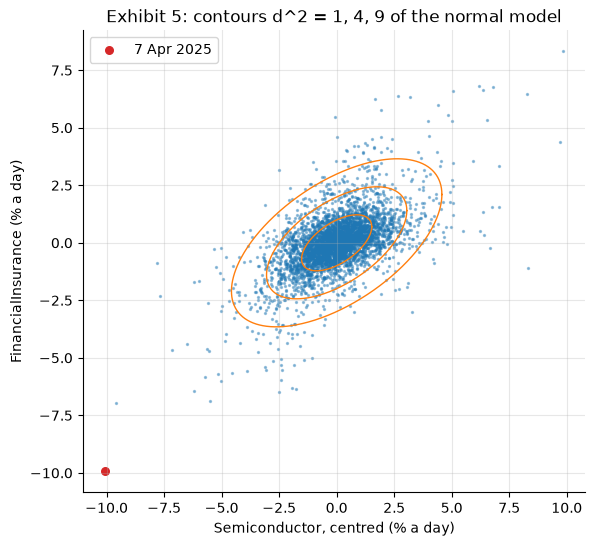

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 6))
Xc = 100 * (XP - XP.mean(axis=0))
ax.scatter(Xc[:, 0], Xc[:, 1], s=2, alpha=0.4)
L2 = np.linalg.cholesky(np.cov(Xc, rowvar=False, ddof=0))
t = np.linspace(0, 2 * np.pi, 400)
for k in (1, 2, 3):
    ring = L2 @ (k * np.vstack([np.cos(t), np.sin(t)]))
    ax.plot(ring[0], ring[1], color="tab:orange", lw=1)
ax.scatter([Xc[i7, 0]], [Xc[i7, 1]], color="tab:red", s=30, label="7 Apr 2025")
ax.set_aspect("equal"); ax.set_xlabel("Semiconductor, centred (% a day)"); ax.set_ylabel("FinancialInsurance (% a day)")
ax.set_title("Exhibit 5: contours d^2 = 1, 4, 9 of the normal model"); ax.legend(); plt.show()

In [17]:
# Problem 8: 5 August 2024 by hand, from printed inputs (LM12's factor entries, % a day)
i5 = dates.index("2024-08-05")
show("Problem 8: Semiconductor, %", 100 * x1[i5], ".2f", "-9.48", kept=True)
show("   FinancialInsurance, %", 100 * x2[i5], ".2f", "-6.93", kept=True)
z1 = (-9.48 - M1) / 1.5243
z2 = (-6.93 - M2 - 0.6998 * z1) / 0.9960
show("   z_1", z1, ".3f", "-6.281", kept=True)
show("   z_2", z2, ".3f", "-2.594", kept=True)
show("   d^2 from printed inputs", z1**2 + z2**2, ".2f", "46.18", kept=True)
show("   d^2 from the data", d2[i5], ".2f", "46.22")
print(f"   e^(-23.09) = {math.exp(-23.09):.1e}; expected such days in 4,382: {4382 * math.exp(-23.09):.0e}")

Problem 8: Semiconductor, %: -9.48   [book: -9.48]
   FinancialInsurance, %: -6.93   [book: -6.93]
   z_1: -6.281   [book: -6.281]
   z_2: -2.594   [book: -2.594]
   d^2 from printed inputs: 46.18   [book: 46.18]
   d^2 from the data: 46.22   [book: 46.22]
   e^(-23.09) = 9.4e-11; expected such days in 4,382: 4e-07


## Part 7 — Correlation in a crash

**Exhibit 9.** The normal benchmark for joint falls has no closed form: integrate over $x\le-k$ the moments of $Y$ given $X=x$, a truncated normal, with `scipy.integrate.quad`. **Exhibit 8** uses (16.10) with the conditional variances of Deep Dive 3. **Example 10** and Problem 10 follow.

In [18]:
def trunc(mu, sd, c):
    # E[1{W<=c}], E[W 1{W<=c}], E[W^2 1{W<=c}] for W ~ N(mu, sd^2)
    a = (c - mu) / sd
    P, p = stats.norm.cdf(a), stats.norm.pdf(a)
    return P, mu * P - sd * p, (mu * mu + sd * sd) * P - sd * (mu + c) * p


def bench_low(rho, k):
    # probability and correlation of a standard normal pair (correlation rho), given both <= -k
    c, sd = -k, math.sqrt(1 - rho * rho)

    def mom(which):
        def f(x):
            p0, p1, p2 = trunc(rho * x, sd, c)
            return stats.norm.pdf(x) * (p0, x * p0, p1, x * x * p0, p2, x * p1)[which]
        return integrate.quad(f, -np.inf, c, epsabs=1e-13, epsrel=1e-11, limit=200)[0]

    P, ex, ey, exx, eyy, exy = (mom(j) for j in range(6))
    vx, vy = exx / P - (ex / P) ** 2, eyy / P - (ey / P) ** 2
    return P, (exy / P - ex * ey / P**2) / math.sqrt(vx * vy)


rho = np.corrcoef(x1, x2)[0, 1]
z1s, z2s = (x1 - x1.mean()) / x1.std(), (x2 - x2.mean()) / x2.std()
rows8 = []
for k in np.arange(0, 2.01, 0.25):
    lo = (z1s <= -k + EPS) & (z2s <= -k + EPS)
    hi = (z1s >= k - EPS) & (z2s >= k - EPS)
    P, bc = bench_low(rho, k)
    rows8.append({"k": k, "falls: days": int(lo.sum()), "falls: corr": np.corrcoef(x1[lo], x2[lo])[0, 1],
                  "rises: days": int(hi.sum()), "rises: corr": np.corrcoef(x1[hi], x2[hi])[0, 1],
                  "benchmark": bc, "model Pr": P, "model days": T * P})
ex8 = pl.DataFrame(rows8)
r0, r1, r2 = rows8[0], rows8[4], rows8[8]
show("Exhibit 9 benchmark at k = 0", r0["benchmark"], ".3f", "0.332")
show("   at k = 1", r1["benchmark"], ".3f", "0.229")
show("   at k = 2", r2["benchmark"], ".3f", "0.156")
show("   joint falls at k=2: days", r2["falls: days"], "d", "44")
show("   joint falls at k=2: corr", r2["falls: corr"], ".3f", "0.669")
show("   joint rises at k=2: days", r2["rises: days"], "d", "32")
show("   joint rises at k=2: corr", r2["rises: corr"], ".3f", "0.541")
show("   model days at k=2", r2["model days"], ".1f", "22.4")
ex8

Exhibit 9 benchmark at k = 0: 0.332   [book: 0.332]
   at k = 1: 0.229   [book: 0.229]
   at k = 2: 0.156   [book: 0.156]
   joint falls at k=2: days: 44   [book: 44]
   joint falls at k=2: corr: 0.669   [book: 0.669]
   joint rises at k=2: days: 32   [book: 32]
   joint rises at k=2: corr: 0.541   [book: 0.541]
   model days at k=2: 22.4   [book: 22.4]


k,falls: days,falls: corr,rises: days,rises: corr,benchmark,model Pr,model days
f64,i64,f64,i64,f64,f64,f64,f64
0.000000,1509,0.575202,1523,0.429691,0.332334,0.347471,1522.619884
0.250000,953,0.564868,948,0.424675,0.303875,0.253846,1112.354831
0.500000,597,0.516806,539,0.457814,0.276977,0.175336,768.322043
0.750000,384,0.521714,303,0.448935,0.251921,0.114163,500.261179
1.000000,228,0.464538,170,0.451798,0.228847,0.069892,306.267099
1.250000,151,0.418598,89,0.450396,0.207788,0.040146,175.920010
1.500000,104,0.458419,55,0.571445,0.188698,0.021596,94.633058
1.750000,64,0.603773,39,0.507947,0.171479,0.010863,47.599514
2.000000,44,0.668968,32,0.541459,0.156001,0.005102,22.356931


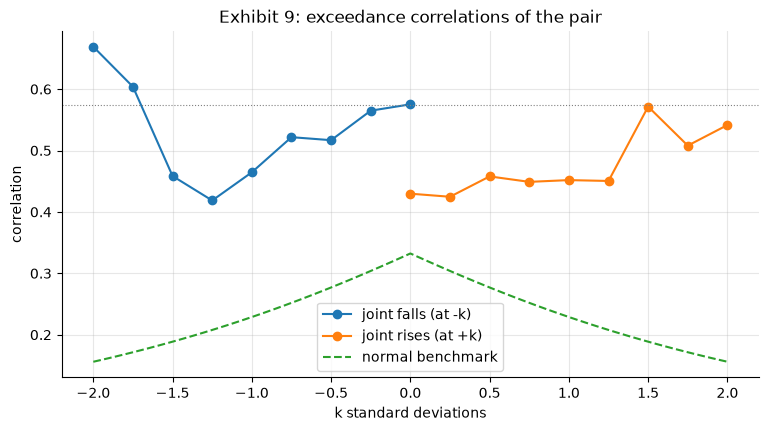

In [19]:
fig, ax = plt.subplots()
ks = ex8["k"].to_numpy()
ax.plot(-ks, ex8["falls: corr"], marker="o", label="joint falls (at -k)")
ax.plot(ks, ex8["rises: corr"], marker="o", label="joint rises (at +k)")
kk = np.linspace(0, 2, 41)
bb = [bench_low(rho, k)[1] for k in kk]
ax.plot(np.r_[-kk[::-1], kk[1:]], np.r_[bb[::-1], bb[1:]], ls="--", label="normal benchmark")
ax.axhline(rho, color="gray", lw=0.8, ls=":")
ax.set_xlabel("k standard deviations"); ax.set_ylabel("correlation")
ax.set_title("Exhibit 9: exceedance correlations of the pair"); ax.legend(); plt.show()

In [20]:
def v_two(k):                     # Var(Z | |Z| >= k)
    return 1 + k * stats.norm.pdf(k) / stats.norm.sf(k)


def v_low(k):                     # Var(Z | Z <= -k)
    ell = stats.norm.pdf(k) / stats.norm.cdf(-k)
    return 1 + k * ell - ell * ell


def bgl(r, v):                    # (16.10) with Var(X) = 1
    return r / math.sqrt(r * r + (1 - r * r) / v)


rows9 = []
for k in (1.0, 2.0, 2.5):
    for name, sel, v in (("either way", np.abs(z1s) >= k - EPS, v_two(k)), ("falls", z1s <= -k + EPS, v_low(k)),
                         ("rises", z1s >= k - EPS, v_low(k))):
        rows9.append({"event": name, "k": k, "days": int(sel.sum()), "data": np.corrcoef(x1[sel], x2[sel])[0, 1],
                      "model (16.10)": bgl(rho, v)})
print(pl.DataFrame(rows9).sort("event", "k"))      # Exhibit 8
show("Var(Z | |Z| >= 2)", v_two(2.0), ".4f", "5.7464")
show("Var(Z | Z <= -2)", v_low(2.0), ".4f", "0.1143")
show("Problem 10: (16.10) with 5.7464", bgl(0.5749, 5.7464), ".3f", "0.860", kept=True)
show("   with 0.1143", bgl(0.5749, 0.1143), ".3f", "0.231", kept=True)
show("knowledge check, Section 7", bgl(0.5749, 2.5251), ".3f", "0.745", kept=True)
for r_, p in zip((-9.95, -3.99, -4.47), ("-6.59", "-2.68", "-2.99")):
    show(f"Example 10 move {r_}% in sd (printed inputs)", (r_ - M1) / S1, ".2f", p, kept=True)

shape: (9, 5)
┌────────────┬──────────┬──────┬──────────┬───────────────┐
│ event      ┆ k        ┆ days ┆ data     ┆ model (16.10) │
│ ---        ┆ ---      ┆ ---  ┆ ---      ┆ ---           │
│ str        ┆ f64      ┆ i64  ┆ f64      ┆ f64           │
╞════════════╪══════════╪══════╪══════════╪═══════════════╡
│ either way ┆ 1.000000 ┆ 1088 ┆ 0.691624 ┆ 0.744868      │
│ either way ┆ 2.000000 ┆ 223  ┆ 0.788446 ┆ 0.859842      │
│ either way ┆ 2.500000 ┆ 111  ┆ 0.811069 ┆ 0.893902      │
│ falls      ┆ 1.000000 ┆ 550  ┆ 0.474048 ┆ 0.299125      │
│ falls      ┆ 2.000000 ┆ 105  ┆ 0.488212 ┆ 0.231069      │
│ falls      ┆ 2.500000 ┆ 47   ┆ 0.485160 ┆ 0.205103      │
│ rises      ┆ 1.000000 ┆ 538  ┆ 0.367136 ┆ 0.299125      │
│ rises      ┆ 2.000000 ┆ 118  ┆ 0.428689 ┆ 0.231069      │
│ rises      ┆ 2.500000 ┆ 64   ┆ 0.381636 ┆ 0.205103      │
└────────────┴──────────┴──────┴──────────┴───────────────┘
Var(Z | |Z| >= 2): 5.7464   [book: 5.7464]
Var(Z | Z <= -2): 0.1143   [book: 0.1143]
P

## Part 8 — Problem 12 and an extension

**Problem 12.** The joint pmf with the guard and with `Fraction` is Part 2. Here: the pair's $d_t^2$, the count beyond 9 against `T * stats.chi2.sf(9, 2)`, and why `1 - cdf` loses a tail that `sf` keeps.

In [21]:
print("days with d^2 > 9:", int((d2 > 9 + EPS).sum()), "| T * chi2.sf(9, 2) =", round(T * stats.chi2.sf(9, 2), 2))
print("1 - chi2.cdf(89.30, 5) =", 1 - stats.chi2.cdf(89.30, 5), "| chi2.sf(89.30, 5) =", stats.chi2.sf(89.30, 5))
print("the largest double below 1 is 1 -", 1 - np.nextafter(1.0, 0.0), ": a cdf within 1e-17 of 1 is stored as 1")

days with d^2 > 9: 177 | T * chi2.sf(9, 2) = 48.68
1 - chi2.cdf(89.30, 5) = 0.0 | chi2.sf(89.30, 5) = 9.426575482464327e-18
the largest double below 1 is 1 - 1.1102230246251565e-16 : a cdf within 1e-17 of 1 is stored as 1


### Extension: the two price-limit regimes (a stability check)

The daily price limit was 7% until 29 May 2015 and 10% from 1 June 2015. Split the sample at that date, keep the **full-sample** standardization and $d_t^2$ (so the two halves are measured with one ruler), and compare the pair's correlation, the days with $d_t^2>9$ and the exceedance correlations of Exhibit 9 in each regime. With every close repaired, the book's figures are $T=1{,}610$ and 2,772, correlations 0.6544 and 0.5564, and 93 and 84 days beyond radius 3. This is a stability check: draw no conclusion about chance from it (LM21, LM22).

In [22]:
reg = np.array([d <= "2015-05-29" for d in dates])
for name, msk in (("2008-12-02 .. 2015-05-29", reg), ("2015-06-01 .. 2026-10-08", ~reg)):
    print(f"{name}: T = {int(msk.sum())}, corr = {np.corrcoef(x1[msk], x2[msk])[0, 1]:.4f}, "
          f"days with d^2 > 9 = {int((d2[msk] > 9 + EPS).sum())}")
if FULL_DATA:
    assert int(reg.sum()) == 1610 and int((~reg).sum()) == 2772
    assert f"{np.corrcoef(x1[reg], x2[reg])[0, 1]:.4f}" == "0.6544" and f"{np.corrcoef(x1[~reg], x2[~reg])[0, 1]:.4f}" == "0.5564"
    assert int((d2[reg] > 9 + EPS).sum()) == 93 and int((d2[~reg] > 9 + EPS).sum()) == 84
# your code: the exceedance correlations of each regime, k = 0, 0.25, ..., 2, beside the full-sample benchmark

2008-12-02 .. 2015-05-29: T = 1610, corr = 0.6544, days with d^2 > 9 = 93
2015-06-01 .. 2026-10-08: T = 2772, corr = 0.5564, days with d^2 > 9 = 84
